In [1]:
from collections import Counter
import itertools
import json
import geopandas as gpd
from glob import glob
import math
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau
import seaborn as sns
import os

In [2]:
acc_corr = "raam60_BEDS"
res_col = "Cost_2"

In [3]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos), sum(hos["BEDS"]))
hos.head()

66 18259


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.89140)


In [4]:
acc = gpd.read_file("../data/accessibility/CookHospitals.gpkg")
acc = acc.set_index("geoid")
cols = list(acc.columns)
cols.remove('geometry')
# acc = normalize_columns(acc, cols)
# drop rows with nan values
acc = acc.dropna(subset=[acc_corr])
print(len(acc))
acc.head()

1315


,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


In [5]:
# only cars
# experiment_paths = glob("../outputs/ParamTest_NoVeh/*")
# experiment_paths = glob("../outputs/ParamTest_OnlyCars/*")
experiment_paths_nv = glob("../outputs/ParamTest_NoVeh5/*")
experiment_paths_oc = glob("../outputs/ParamTest_OnlyCars5/*")
# print(len(experiment_paths))
experiment_paths = {'noveh': experiment_paths_nv, 'onlycars': experiment_paths_oc}
# experiment_paths = {'onlycars': experiment_paths_oc}

In [6]:
# params tested
cost_funcs = ["raam", "gravity"]
noveh = ['onlycars', 'noveh']
# noveh = ['onlycars']
timesteps = [10, 15, 20, 25, 30]
topK = [1, 2, 3, 4, 5]
numAgents = [1000, 100, 10, 1]

In [7]:
# quick sanity check
cf_counter, ts_counter, tk_counter, na_counter = Counter(), Counter(), Counter(), Counter()
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    #     print(cf, ts, tk, na)
        cf_counter[cf] +=1
        ts_counter[ts] +=1
        tk_counter[tk] +=1
        na_counter[na] +=1
# you should see even numbers for all parameter options
cf_counter, ts_counter, tk_counter, na_counter

(Counter({'raam': 1000, 'gravity': 1000}),
 Counter({10: 400, 25: 400, 20: 400, 30: 400, 15: 400}),
 Counter({5: 400, 2: 400, 3: 400, 1: 400, 4: 400}),
 Counter({1000: 500, 10: 500, 100: 500, 1: 500}))

In [8]:
def calculate_corrs(acc_corr, res_col):
    experiment_corr = dict()
    for k, v in experiment_paths.items():
        for path in v:
            # load the parameter json
            param_path = os.path.join(path, "parameters.json")
            param_file = open(param_path)
            params = json.load(param_file)
            cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            # join with accessibility data on GEOID
            # join the last time step's cost
            merged = pd.merge(acc[[acc_corr]], results[[res_col]], left_index=True, right_index=True)
        #     print(len(merged))
            corr_res = kendalltau(merged[acc_corr], merged[res_col])
            try:
                experiment_corr[k, cf, ts, tk, na].append(corr_res.correlation)
            except:
                experiment_corr[k, cf, ts, tk, na] = [corr_res.correlation]
    return experiment_corr

In [9]:
experiment_corr = calculate_corrs(acc_corr, res_col)
experiment_corr

{('noveh', 'raam', 10, 5, 1000): [0.6255453119664797,
  0.6214710256899953,
  0.6199848371732323,
  0.6218622497699532,
  0.6221354121453084],
 ('noveh', 'gravity', 10, 2, 10): [0.6793258908160725,
  0.6784601049823197,
  0.6775989490193354,
  0.6793860791360661,
  0.6777239555300912],
 ('noveh', 'gravity', 10, 3, 100): [0.6836849141448338,
  0.6814602612404581,
  0.6859350313384377,
  0.6838261252032802,
  0.6886643401566053],
 ('noveh', 'gravity', 25, 2, 100): [0.6838515894925082,
  0.6837589920771335,
  0.6801106539113726,
  0.6889236129196543,
  0.6844349532093684],
 ('noveh', 'raam', 10, 3, 10): [0.7517833683467309,
  0.7484498613932438,
  0.7447806888090236,
  0.7561771157062578,
  0.7446649420398052],
 ('noveh', 'raam', 20, 2, 10): [0.8524529634066589,
  0.851809411369805,
  0.854515570834129,
  0.8537215479972914,
  0.8523626809266686],
 ('noveh', 'gravity', 10, 3, 1): [0.7015284360875277,
  0.7019844783582477,
  0.7006094067399342,
  0.7011603613614135,
  0.7013200919029347],


In [10]:
std_devs = []
for key, val in experiment_corr.items():
    std_devs.append(np.std(val))

(array([297.,  58.,  25.,   8.,   7.,   2.,   0.,   1.,   1.,   1.]),
 array([0.        , 0.00287262, 0.00574524, 0.00861785, 0.01149047,
        0.01436309, 0.01723571, 0.02010832, 0.02298094, 0.02585356,
        0.02872618]),
 <BarContainer object of 10 artists>)

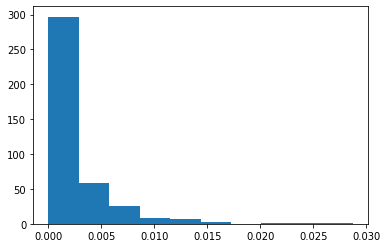

In [11]:
plt.hist(std_devs)

In [12]:
corrs = {'raam': [], 'gravity': []}
for k, v in experiment_corr.items():
    corrs[k[1]].extend(v)
print(min(corrs['raam']), min(corrs['gravity']))
print(max(corrs['raam']), max(corrs['gravity']))

0.6199848371732323 0.5833174663208934
0.9077542412632414 0.7436185912460717


In [13]:
_min = math.floor(min([min(corrs['raam']), min(corrs['gravity'])])*10)/10.0
_max = math.ceil(max([max(corrs['raam']), max(corrs['gravity'])])*10)/10.0
print(_min, _max)

0.5 1.0


In [14]:
def get_ylims(ecorr):
    corrs = {'raam': [], 'gravity': []}
    for k, v in ecorr.items():
        corrs[k[1]].extend(v)
    _min = math.floor(min([min(corrs['raam']), min(corrs['gravity'])])*10)/10.0
    _max = math.ceil(max([max(corrs['raam']), max(corrs['gravity'])])*10)/10.0
    return(_min, _max)

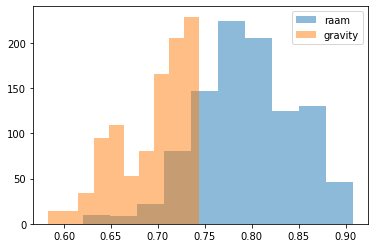

In [15]:
plt.hist(corrs['raam'], alpha=0.5, label='raam')
plt.hist(corrs['gravity'], alpha=0.5, label='gravity')
plt.legend(loc='upper right')
plt.show()

In [16]:
def parameter_boxplots(experiment_corr):
    fig, axes = plt.subplots(4, 3, figsize=(14, 12))
    ylims = get_ylims(experiment_corr)
    colors = [
        ["#6267f5", "#6cf562"],
        ["#f56462", "#f5a462"]
    ]

    fsize = 22
    for i, cf in enumerate(cost_funcs):
        for j, nv in enumerate(noveh):
            # get the ax for numAgents
            ax = axes[i*2 + j, 0]
            parameters = numAgents
            oparameters = (timesteps, topK)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, a, b, p])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, labels=x_labels)
    #         ax.set_title("Correlations by PopPerAgent")
            ax.set_ylim(*ylims)
#             if not (i == 1 and j == 1):
#                 ax.set_xticklabels([])
            # get the ax for topk
            ax = axes[i*2 + j, 1]
            parameters = topK
            oparameters = (timesteps, numAgents)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, a, p, b])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, labels=x_labels)
#             if not (i == 1 and j == 1):
#                 ax.set_xticklabels([])
            ax.set_yticklabels([])
    #         ax.set_title("Correlations by topK")
            ax.set_ylim(*ylims)
            # get the ax for timesteps
            ax = axes[i*2 + j, 2]
            parameters = timesteps
            oparameters = (topK, numAgents)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, p, a, b])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, labels=x_labels)
    #         ax.set_title("Correlations by Time Steps")
            ax.set_ylim(*ylims)
#             if not (i == 1 and j == 1):
#                 ax.set_xticklabels([])
            ax.set_yticklabels([])

    for ax in axes.flatten():
        ax.tick_params(axis='both', which='major', labelsize=fsize-4)
        ax.grid('on')

    clabels = ["Correlations by PopPerAgent", "Correlations by topK", "Correlations by Time Steps"]
    for ax, clab in zip(axes[0], clabels):
        ax.set_title(clab, fontsize=fsize)
    rlabels = ["RAAM, Cars", "RAAM, NoVeh", "Gravity, Cars", "Gravity, NoVeh"]
    for ax, lab in zip(axes[:, 0], rlabels):
        ax.set_ylabel(lab, fontsize=fsize)

    # spacer = "     "
    # fig.suptitle(f"Correlations between Results and RAAM by Parameter\nGravity{spacer}vs.{spacer}RAAM", fontsize=24)
    # fig.supylabel(f"Census-based No Vehicle{spacer}vs.{spacer}Only Cars", fontsize=24)

    plt.subplots_adjust(wspace=0, hspace=0)
    fig.tight_layout()
    plt.show()

gravity_BEDS


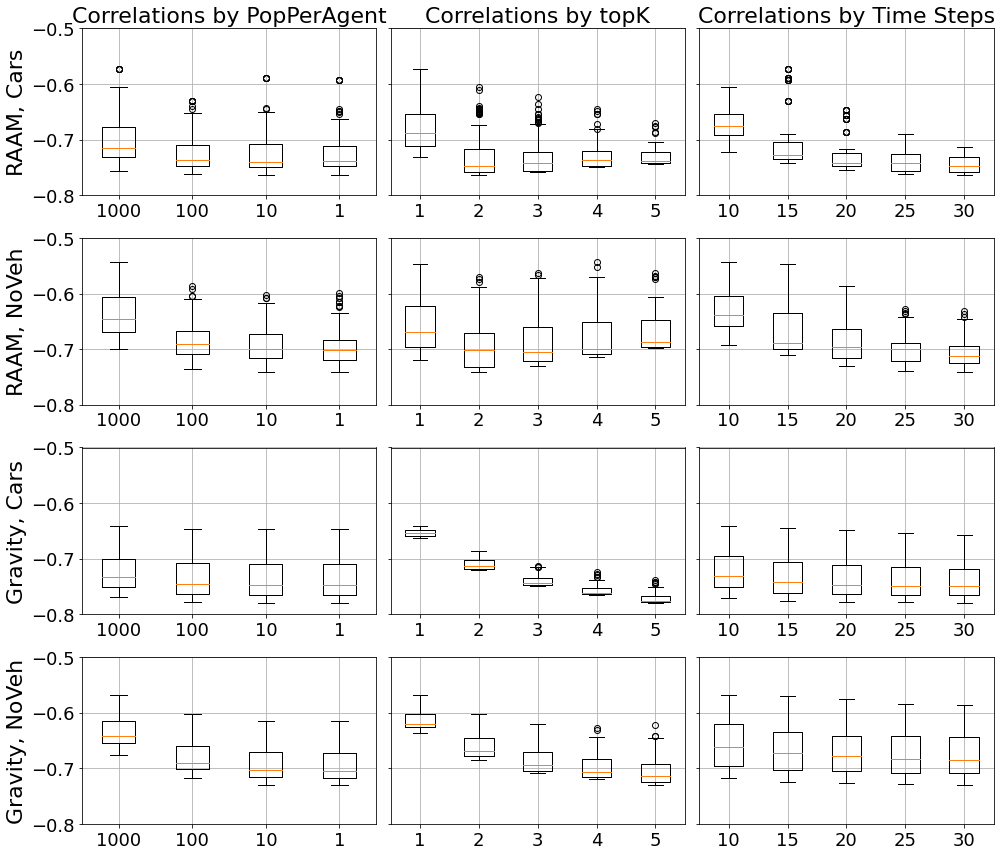

raam60_BEDS


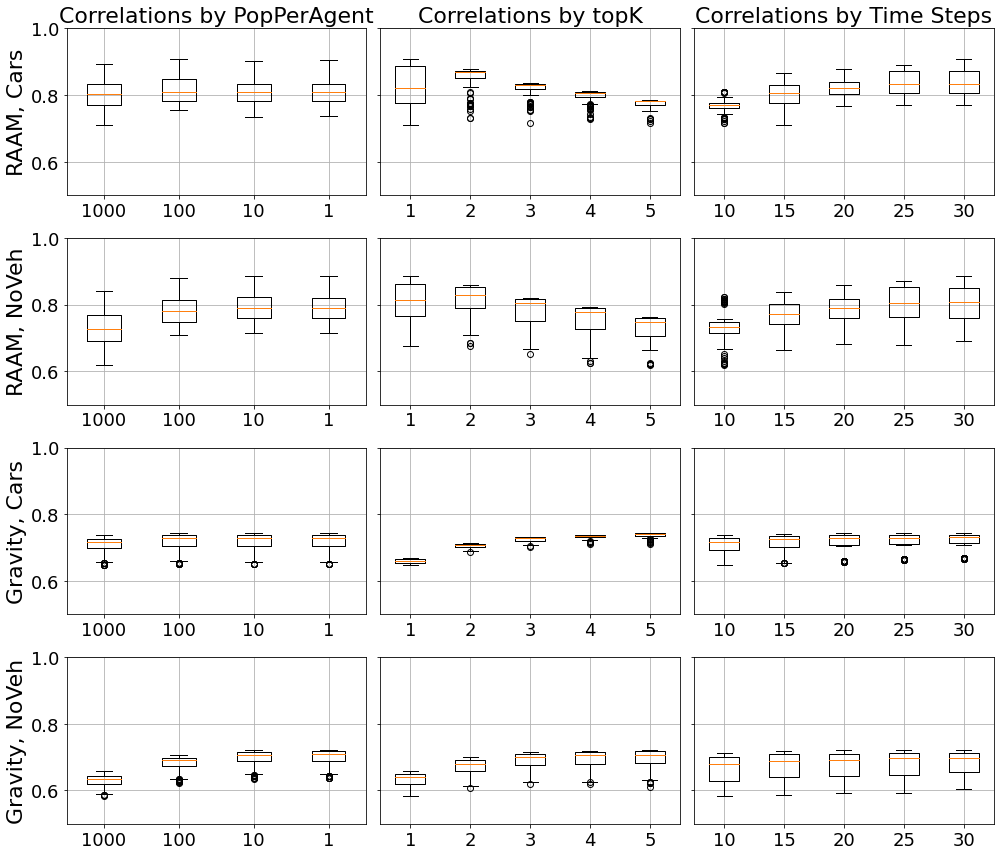

In [17]:
# for acc_col in cols:
for acc_col in ['raam60_BEDS']:
    print(acc_col)
    experiment_corr = calculate_corrs(acc_col, res_col)
    parameter_boxplots(experiment_corr)

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


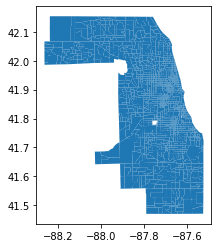

In [18]:
mean_costs = acc.copy(deep=True)
mean_costs.plot()
mean_costs.head()

In [19]:
mean_costs_raam = acc.copy(deep=True)
cost_dict = {x: [] for x in mean_costs.index}
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
        if cf == "raam":
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            for index, row in results.iterrows():
                try:
                    cost_dict[index].append(row[res_col])
                except:
                    cost_dict[index] = []
                    cost_dict[index].append(row[res_col])
                    

In [20]:
# cost_dict

In [21]:
avg_costs = {key: np.mean(val) for key, val in cost_dict.items()}

In [22]:
avg_cost_df = pd.DataFrame.from_dict(avg_costs, orient='index', columns=['avgCost'])
avg_cost_df.head()

,avgCost
17031010100,1.166667
17031010201,1.141199
17031010202,1.170808
17031010300,1.185694
17031010400,1.201372


In [23]:
merged = acc.merge(avg_cost_df, left_index=True, right_index=True)
merged.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,avgCost
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019...",1.166667
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019...",1.141199
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012...",1.170808
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015...",1.185694
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009...",1.201372


<Axes: >

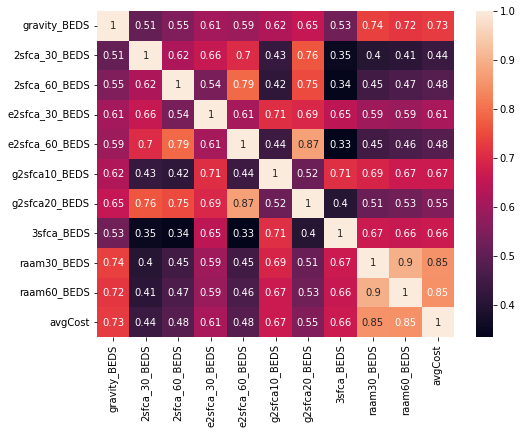

In [24]:
tmp = merged.drop(columns=["geometry"])
to_negate = ['raam30_BEDS', 'raam60_BEDS', 'avgCost']
for col in to_negate:
    tmp[col] = - tmp[col]
corr = tmp.corr(method='kendall')
fig, ax = plt.subplots(figsize=(8, 6))  
sns.heatmap(corr, annot=True, ax=ax)

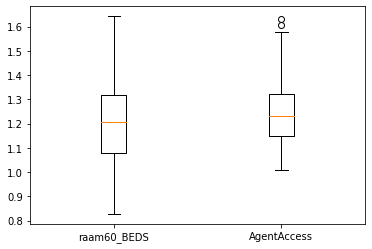

In [25]:
plt.boxplot([merged[acc_corr], merged["avgCost"]], labels=[acc_corr, "AgentAccess"])
# plt.hist(merged[acc_corr], alpha=0.5, label=acc_corr)
# plt.hist(merged["avgCost"], alpha=0.5, label="AgentAccess")
# plt.legend(loc='upper right')
plt.show()

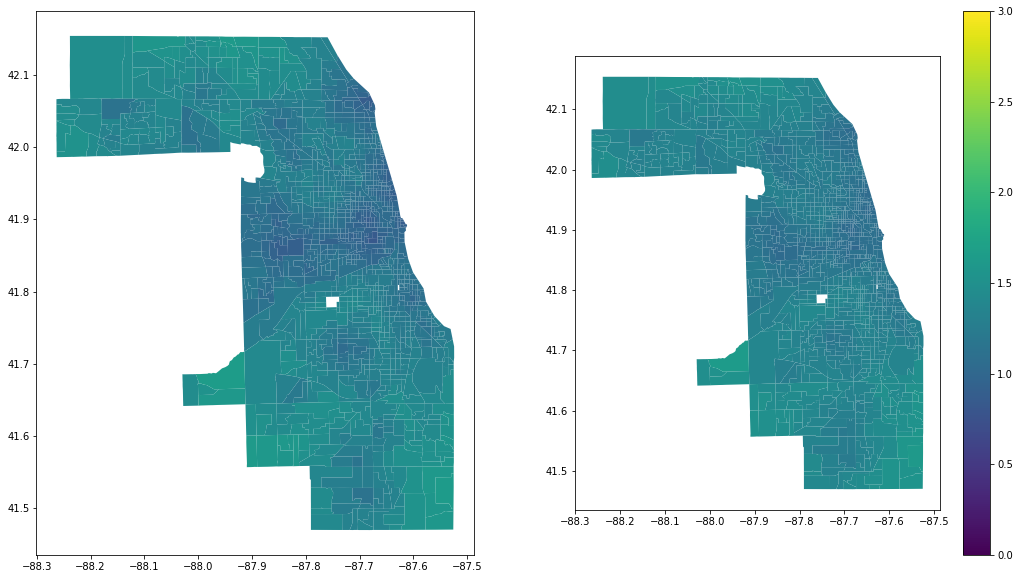

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(18, 10))
merged.plot(ax=axes[0], column=acc_corr, vmin=0, vmax=3)
merged.plot(ax=axes[1], column="avgCost", vmin=0, vmax=3, legend=True)
plt.show()

<Axes: >

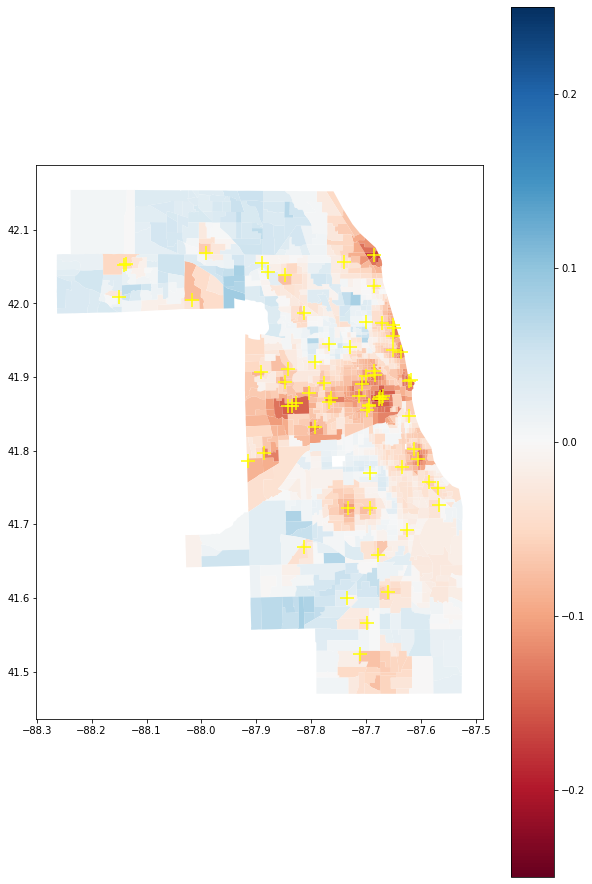

In [55]:
merged["diff"] = (merged[acc_corr] - merged['avgCost']) / ((merged[acc_corr] + merged['avgCost']) / 2.0)
ax = merged.plot(column='diff', figsize=(10, 16), legend=True, cmap="RdBu", vmin=-.25, vmax=.25)
hos.plot(ax=ax, color='yellow', marker='+', markersize=200)
# merged.head()

# Mean costs by top k

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


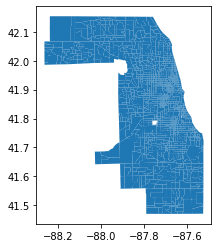

In [28]:
mean_costs_byk = acc.copy(deep=True)
mean_costs_byk.plot()
mean_costs_byk.head()

In [29]:
cost_dict = {x: dict() for x in mean_costs.index}
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
        if cf == "raam":
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            for index, row in results.iterrows():
                try:
                    cost_dict[index][tk].append(row[res_col])
                except:
                    try:
                        cost_dict[index][tk] = []
                    except:
                        cost_dict[index] = dict()
                        cost_dict[index][tk] = []
                    cost_dict[index][tk].append(row[res_col])
                    

In [30]:
# list comprehensions can become very dumb
avg_costs_byk = {key: [np.mean(ival) for ikey, ival in val.items()] for key, val in cost_dict.items()}

In [31]:
avg_cost_byk_df = pd.DataFrame.from_dict(avg_costs_byk, orient='index', columns=[f'avgCost_{k}' for k in topK])
avg_cost_byk_df.head()

,avgCost_1,avgCost_2,avgCost_3,avgCost_4,avgCost_5
17031010100,1.251068,1.179631,1.130396,1.219822,1.052419
17031010201,1.221434,1.156971,1.110612,1.192841,1.024140
17031010202,1.241407,1.183216,1.144693,1.216777,1.067944
17031010300,1.254807,1.193874,1.163904,1.227713,1.088171
17031010400,1.250064,1.212263,1.201113,1.233594,1.109826


In [32]:
merged_byk = acc.merge(avg_cost_byk_df, left_index=True, right_index=True)
merged_byk.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,avgCost_1,avgCost_2,avgCost_3,avgCost_4,avgCost_5
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019...",1.251068,1.179631,1.130396,1.219822,1.052419
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019...",1.221434,1.156971,1.110612,1.192841,1.024140
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012...",1.241407,1.183216,1.144693,1.216777,1.067944
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015...",1.254807,1.193874,1.163904,1.227713,1.088171
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009...",1.250064,1.212263,1.201113,1.233594,1.109826


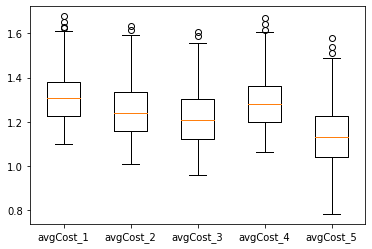

In [33]:
data, labels = [], []
for k in topK:
    data.append(merged_byk[f"avgCost_{k}"])
    labels.append(f"avgCost_{k}")
plt.boxplot(data, labels=labels)
plt.show()

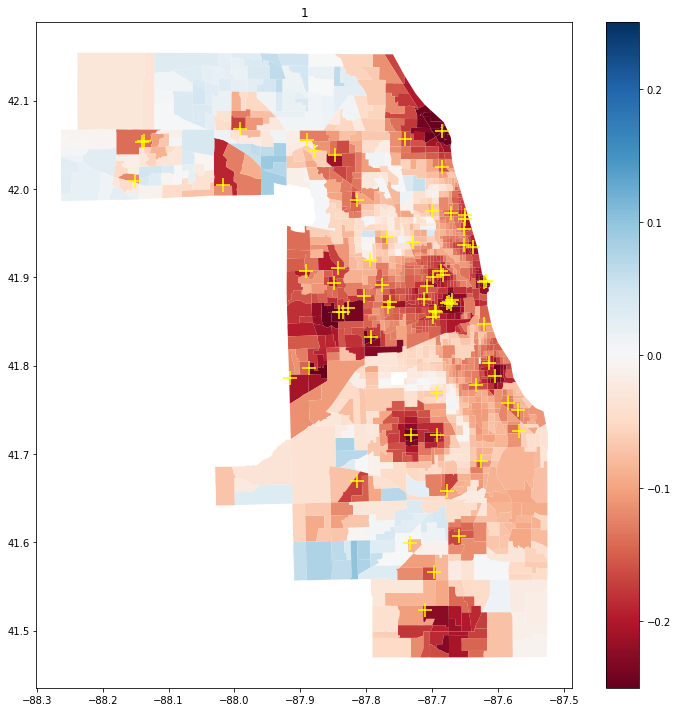

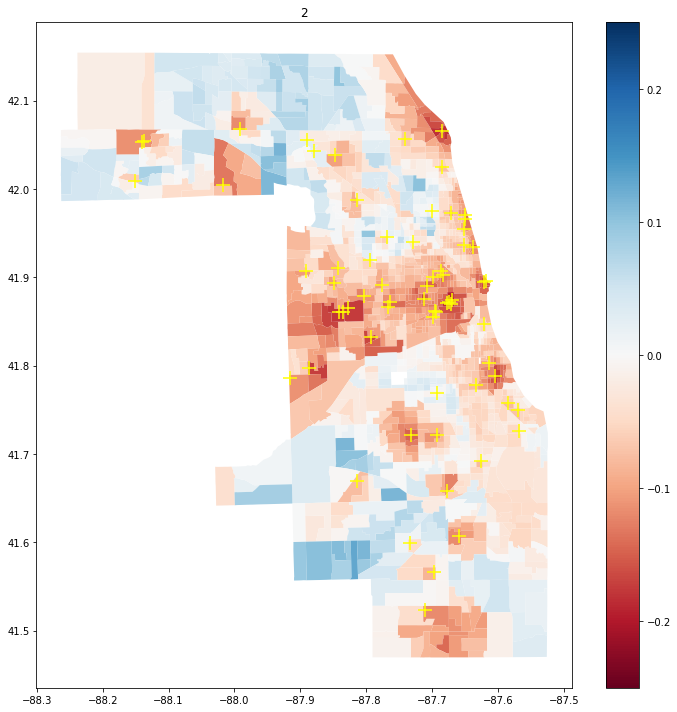

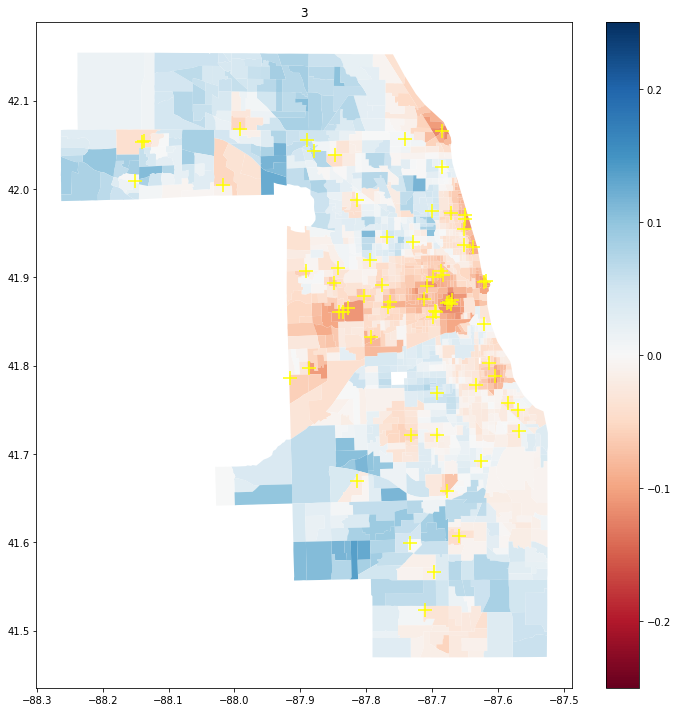

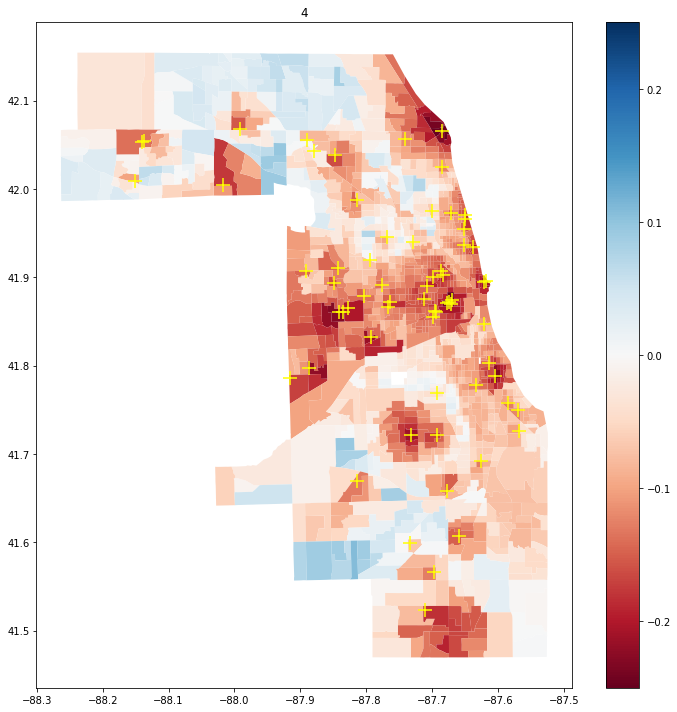

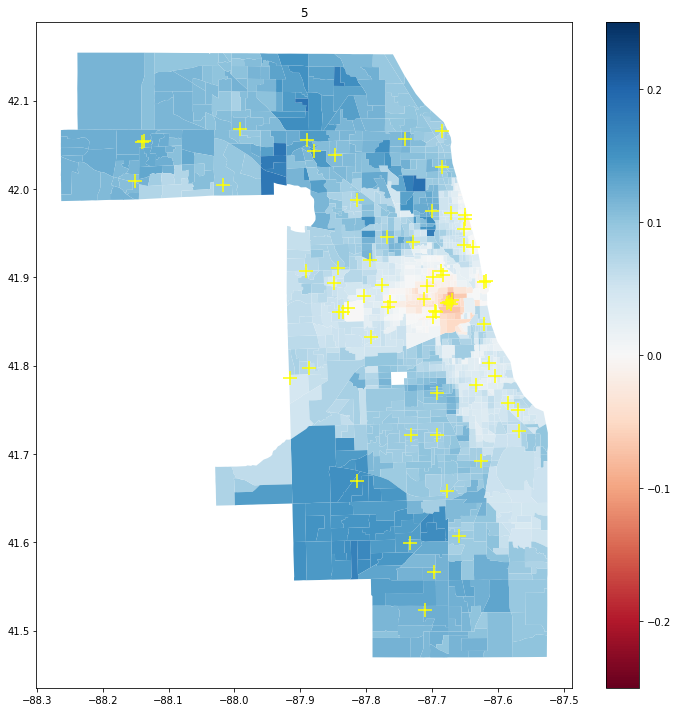

In [34]:
for k in topK:
    merged_byk[f"diff_{k}"] = merged_byk[acc_corr] - merged_byk[f'avgCost_{k}']
    ax = merged_byk.plot(column=f"diff_{k}", figsize=(10, 10), legend=True, cmap="RdBu", vmin=-.25, vmax=.25)
    hos.plot(ax=ax, color='yellow', marker='+', markersize=200)
    # merged.head()
    plt.title(k)
    plt.tight_layout()
    plt.show()

# Mean costs NoVeh vs. OnlyCars

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


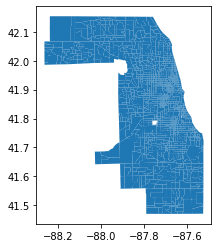

In [35]:
mean_costs_cars = acc.copy(deep=True)
mean_costs_cars.plot()
mean_costs_cars.head()

In [36]:
cost_dict = {x: {'noveh': [], 'onlycars': []} for x in mean_costs.index}
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
        if cf == "raam":
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            # drop the ones that don't have population
            results = results[results.index.isin(mean_costs.index)]
            assert max(results[res_col]) < 10
            for index, row in results.iterrows():
                cost_dict[index][k].append(row[res_col])
                    

In [37]:
# list comprehensions can become very dumb
avg_costs_by_cars = {key: [np.mean(ival) for ikey, ival in val.items()] for key, val in cost_dict.items()}

In [38]:
avg_costs_by_cars

{'17031010100': [1.1851867506575162, 1.1481479091088262],
 '17031010201': [1.1536160775234126, 1.1287829183189073],
 '17031010202': [1.1810147019472534, 1.1606003617306848],
 '17031010300': [1.2004496965270204, 1.1709376833334684],
 '17031010400': [1.2174263880408422, 1.1853176074641678],
 '17031010501': [1.2546251881202297, 1.1869183150921394],
 '17031010502': [1.2577547462874177, 1.1867725950323988],
 '17031010503': [1.2213440860315246, 1.1616540282388819],
 '17031010600': [1.2326029406142751, 1.176407233600387],
 '17031010701': [1.16644668592469, 1.1465887741482894],
 '17031010702': [1.2026269918271775, 1.1733023889853276],
 '17031020100': [1.1460708293726456, 1.1246044196232106],
 '17031020200': [1.1541687035268078, 1.1456995364741487],
 '17031020301': [1.2162326152834915, 1.1901700676070308],
 '17031020302': [1.1829581947545214, 1.1634104656123814],
 '17031020400': [1.1647904101978193, 1.145951200198599],
 '17031020500': [1.1946184969509952, 1.1709221965648584],
 '17031020601': [1

In [39]:
avg_costs_by_cars_df = pd.DataFrame.from_dict(avg_costs_by_cars, orient='index', columns=['noveh', 'onlycars'])
avg_costs_by_cars_df.head()

,noveh,onlycars
17031010100,1.185187,1.148148
17031010201,1.153616,1.128783
17031010202,1.181015,1.160600
17031010300,1.200450,1.170938
17031010400,1.217426,1.185318


In [40]:
merged_by_car = acc.merge(avg_costs_by_cars_df, left_index=True, right_index=True)
merged_by_car.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,noveh,onlycars
geoid,,,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019...",1.185187,1.148148
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019...",1.153616,1.128783
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012...",1.181015,1.160600
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015...",1.200450,1.170938
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009...",1.217426,1.185318


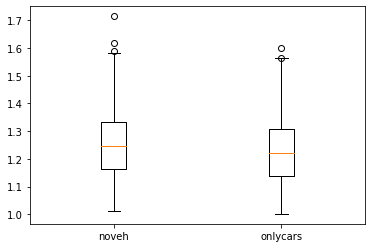

In [41]:
data, labels = [], []
for k in ['noveh', 'onlycars']:
    data.append(merged_by_car[k])
    labels.append(k)
plt.boxplot(data, labels=labels)
plt.show()

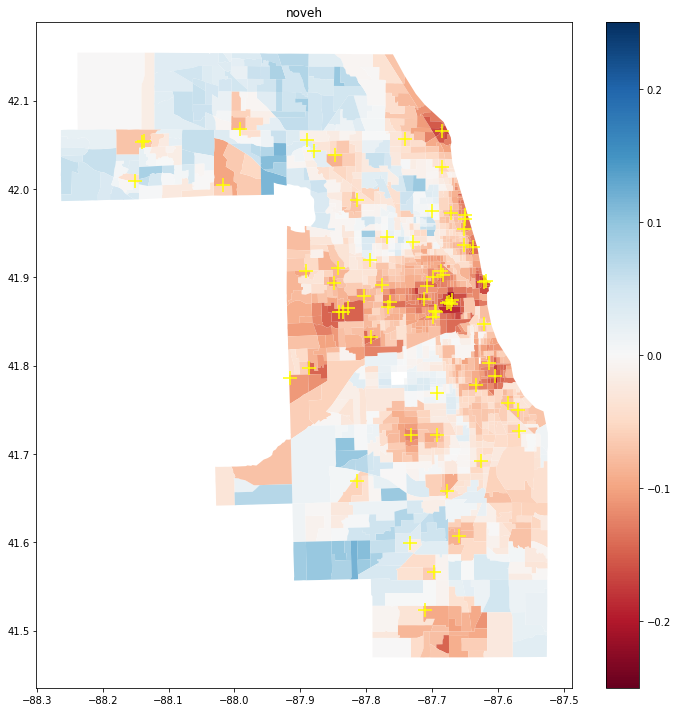

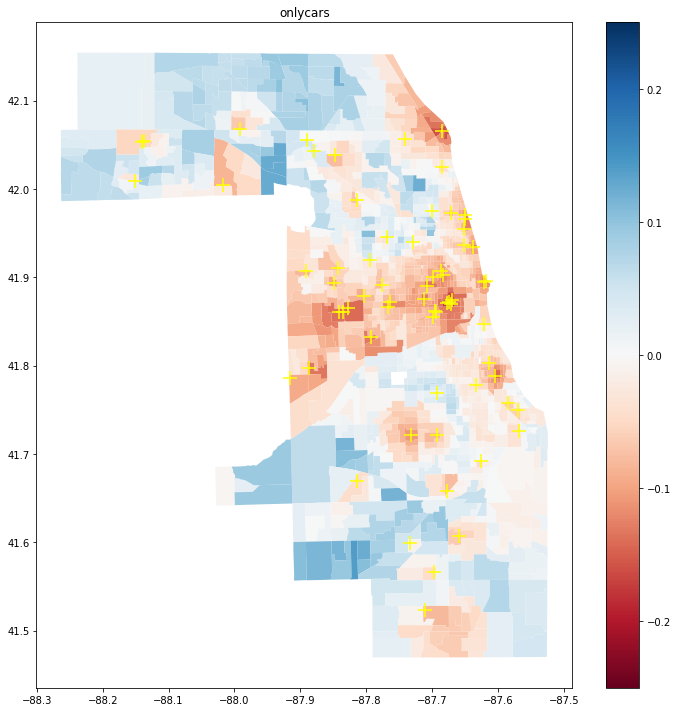

In [42]:
for k in ['noveh', 'onlycars']:
    merged_by_car[f"diff_{k}"] = merged_by_car[acc_corr] - merged_by_car[f'{k}']
    ax = merged_by_car.plot(column=f"diff_{k}", figsize=(10, 10), legend=True, cmap="RdBu", vmin=-.25, vmax=.25)
    hos.plot(ax=ax, color='yellow', marker='+', markersize=200)
    # merged.head()
    plt.title(k)
    plt.tight_layout()
    plt.show()

In [43]:
x = gpd.read_file("../data/svi/SVI2018_US_tract.shp")

In [44]:
x.head()

,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
0,01,ALABAMA,AL,01015,Calhoun,01015981901,"Census Tract 9819.01, Calhoun County, Alabama",24.243865,0,12,...,-999,-999,0,12,-999.0,-999.0,656,0.006105,0.339400,"POLYGON ((-86.01323 33.68426, -86.01224 33.687..."
1,01,ALABAMA,AL,01015,Calhoun,01015981902,"Census Tract 9819.02, Calhoun County, Alabama",34.646714,0,12,...,-999,-999,0,12,-999.0,-999.0,146,0.008752,0.420459,"POLYGON ((-86.01730 33.69662, -86.01704 33.698..."
2,01,ALABAMA,AL,01015,Calhoun,01015981903,"Census Tract 9819.03, Calhoun County, Alabama",13.926276,0,12,...,-999,-999,0,12,-999.0,-999.0,0,0.003508,0.330164,"POLYGON ((-85.78501 33.66554, -85.78318 33.666..."
3,01,ALABAMA,AL,01097,Mobile,01097003605,"Census Tract 36.05, Mobile County, Alabama",0.732300,899,316,...,-999,-999,33,36,3.7,4.1,5135,0.000180,0.060725,"POLYGON ((-88.19230 30.69524, -88.19097 30.695..."
4,01,ALABAMA,AL,01097,Mobile,01097990000,"Census Tract 9900, Mobile County, Alabama",0.000000,0,12,...,-999,-999,0,12,-999.0,-999.0,0,0.000536,0.105380,"MULTIPOLYGON (((-88.05337 30.50699, -88.05109 ..."


/home/dijkstra/.local/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


<Axes: >

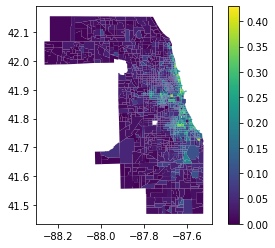

In [52]:
tmp = x[x['STCNTY'] == '17031']
tmp["NOVEHDEN"] = tmp["E_NOVEH"] / tmp["E_TOTPOP"]
tmp.plot('NOVEHDEN', legend=True)

<Axes: >

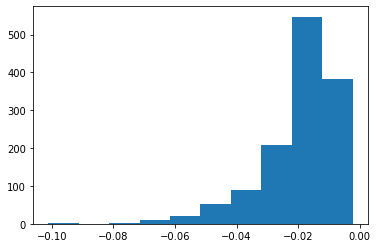

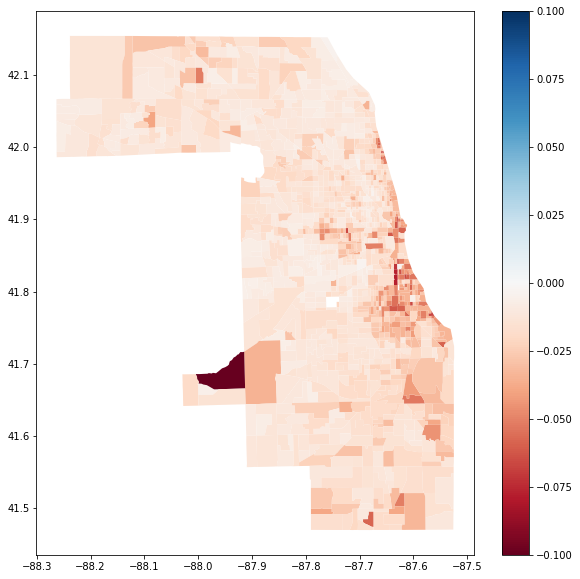

In [58]:
merged_by_car['diffcars'] = (merged_by_car['onlycars'] - merged_by_car['noveh']) / ((merged_by_car['onlycars'] + merged_by_car['noveh']) / 2.0)
plt.hist(merged_by_car['diffcars'])
merged_by_car.plot('diffcars', figsize=(10, 10), legend=True, cmap="RdBu", vmin=-.1, vmax=.1)